In [ ]:
import numpy as np
import pandas as pd
from math import sqrt
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
import math
from sklearn.metrics import mean_squared_error
from numpy import array
from sklearn.neural_network import MLPRegressor
from sklearn.neighbors import KNeighborsRegressor
from scipy.stats import pearsonr
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVC
from sklearn.svm import SVR
from xgboost import XGBClassifier

from sklearn import preprocessing
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.metrics import mean_squared_log_error
from numpy import array
from scipy.stats import kurtosis, skew

In [ ]:
def split_sequences(sequences, n_steps_in, n_steps_out):
  X, y = list(), list()
  for i in range(len(sequences)):
    # find the end of this pattern
    end_ix = i + n_steps_in
    out_end_ix = end_ix + n_steps_out
    # check if we are beyond the dataset
    if out_end_ix > len(sequences):
      break
    # gather input and output parts of the pattern
    seq_x, seq_y = sequences[i:end_ix, :-1], sequences[out_end_ix - 1, -1]
    X.append(seq_x)
    y.append(seq_y)
  return array(X), array(y)

In [ ]:
def stats_features(input_data):
  inp = list()
  for i in range(len(input_data)):
    inp2=list()
    inp2=input_data[i]
    min=float(np.min(inp2))
    max=float(np.max(inp2))
    diff=(max-min)
    std=float(np.std(inp2))
    mean=float(np.mean(inp2))
    median=float(np.median(inp2))
    kurt=float(kurtosis(inp2))
    sk=float(skew(inp2))
    inp2=np.append(inp2,min)
    inp2=np.append(inp2,max)
    inp2=np.append(inp2,diff)
    inp2=np.append(inp2,std)
    inp2=np.append(inp2,mean)
    inp2=np.append(inp2,median)
    inp2=np.append(inp2,kurt)
    inp2=np.append(inp2,sk)
    #print(list(inp2))
    inp=np.append(inp,inp2)
  inp=inp.reshape(len(input_data),-1)
  #print(inp)
  return inp

In [ ]:
def mlp (X_train, X_test, y_train, y_test):
  #mlp = multilayer perceptron / neural network for regression.
  #to setup parameter, please refer to = https://scikit-learn.org/stable/modules/generated/sklearn.neural_ne
  mlp_model = MLPRegressor(random_state=42)
  #mlp_model = MLPRegressor(hidden_layer_sizes=(100,100, ), max_iter=1000, random_state=42)
  #the model learning from training data
  mlp_model.fit(X_train, y_train)
  #get the prediction output
  y_pred = mlp_model.predict(X_test)
  y_pred = np.round(y_pred, 0)
  #get the root mean square error between prediction and real test data
  rmse = sqrt(mean_squared_error(y_test, y_pred))
  #get the pearson correlation
  corr, p_value = pearsonr(y_test, y_pred)
  #returning the output of RMSE, corr, and prediction result
  return rmse, corr, y_pred

In [ ]:
def knn (X_train, X_test, y_train, y_test):
 #k nearest neighbor for regression.
 #to setup the parameter please refer to : https://scikit-learn.org/stable/modules/generated/sklearn.neighb
 knn_model = KNeighborsRegressor()
 #the model is learning from training data
 knn_model.fit(X_train,  y_train)
 #get the prediction output
 y_pred = knn_model.predict(X_test)
 y_pred = np.round(y_pred, 0)
 #get the root mean square error between prediction and real test data
 rmse = sqrt(mean_squared_error(y_test, y_pred))
 #get the pearson correlation
 corr, p_value = pearsonr(y_test, y_pred)
 #returning the output of RMSE, corr, and prediction result
 return rmse, corr, y_pred

In [ ]:
def dt (X_train, X_test, y_train, y_test):
 model= DecisionTreeRegressor(random_state=42)
 model.fit(X_train, y_train)
 y_pred = model.predict(X_test)
 y_pred = np.round(y_pred, 0)
 rmse = sqrt(mean_squared_error(y_test, y_pred))
 #get the pearson correlation
 corr, p_value = pearsonr(y_test, y_pred)
 #returning the output of RMSE, corr, and prediction result
 return rmse, corr, y_pred

In [ ]:
def svm (X_train, X_test, y_train, y_test):
 model=SVR()
 model.fit(X_train, y_train)
 y_pred = model.predict(X_test)
 y_pred = np.round(y_pred, 0)
 rmse = sqrt(mean_squared_error(y_test, y_pred))
 #get the pearson correlation
 corr, p_value = pearsonr(y_test, y_pred)
 #returning the output of RMSE, corr, and prediction result
 return rmse, corr, y_pred

In [ ]:
def rf (X_train, X_test, y_train, y_test):
 model=RandomForestRegressor(random_state=42)
 model.fit(X_train, y_train)
 y_pred = model.predict(X_test)
 y_pred = np.round(y_pred, 0)
 rmse = sqrt(mean_squared_error(y_test, y_pred))
 #get the pearson correlation
 corr, p_value = pearsonr(y_test, y_pred)
 #returning the output of RMSE, corr, and prediction result
 return rmse, corr, y_pred

In [ ]:
import pandas as pd

df = pd.read_csv('https://raw.githubusercontent.com/ganjar87/data_science_practice/main/bikesharing_day.csv')
df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,1/1/2011,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,1/2/2011,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,1/3/2011,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,1/4/2011,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,1/5/2011,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [ ]:
df_ori = df

df_ori['date'] = pd.to_datetime(df_ori['dteday'])
df_ori['cnt'].iloc[:10]

,cnt
0,985
1,801
2,1349
3,1562
4,1600
5,1606
6,1510
7,959
8,822
9,1321


In [ ]:
df_X = df_ori[['cnt','cnt']]
in_seq = df_X.astype(float).values
#out_seq = df_y.astype(float).values

#in_seq1 = in_seq.reshape(in_seq.shape[0], in_seq.shape[1])
#out_seq = out_seq.reshape((len(out_seq), 1))

#from numpy import hstack
#dataset = hstack((in_seq1, out_seq))

n_steps_in, n_steps_out = 7, 1
X, y = split_sequences(in_seq, n_steps_in, n_steps_out)

n_input = X.shape[1] * X.shape[2]
X = X.reshape((X.shape[0], n_input))

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, shuffle = False)
X_train = stats_features(X_train)
X_test = stats_features(X_test)

In [ ]:
in_seq

array([[ 985.,  985.],
       [ 801.,  801.],
       [1349., 1349.],
       ...,
       [1341., 1341.],
       [1796., 1796.],
       [2729., 2729.]])

In [ ]:
X

array([[ 985.,  801., 1349., ..., 1600., 1606., 1510.],
       [ 801., 1349., 1562., ..., 1606., 1510.,  959.],
       [1349., 1562., 1600., ..., 1510.,  959.,  822.],
       ...,
       [1749., 1787.,  920., ...,  441., 2114., 3095.],
       [1787.,  920., 1013., ..., 2114., 3095., 1341.],
       [ 920., 1013.,  441., ..., 3095., 1341., 1796.]])

In [ ]:
X.shape

(724, 7)

In [ ]:
X[0]

array([ 985.,  801., 1349., 1562., 1600., 1606., 1510.])

In [ ]:
y[0]

np.float64(959.0)

In [ ]:
df_new=df_ori[['date','cnt']]
df_new.set_index('date')

,cnt
date,
2011-01-01,985
2011-01-02,801
2011-01-03,1349
2011-01-04,1562
2011-01-05,1600
...,...
2012-12-27,2114
2012-12-28,3095
2012-12-29,1341


/tmp/ipython-input-2331769385.py:6: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(loc='upper left',  fontsize=15)


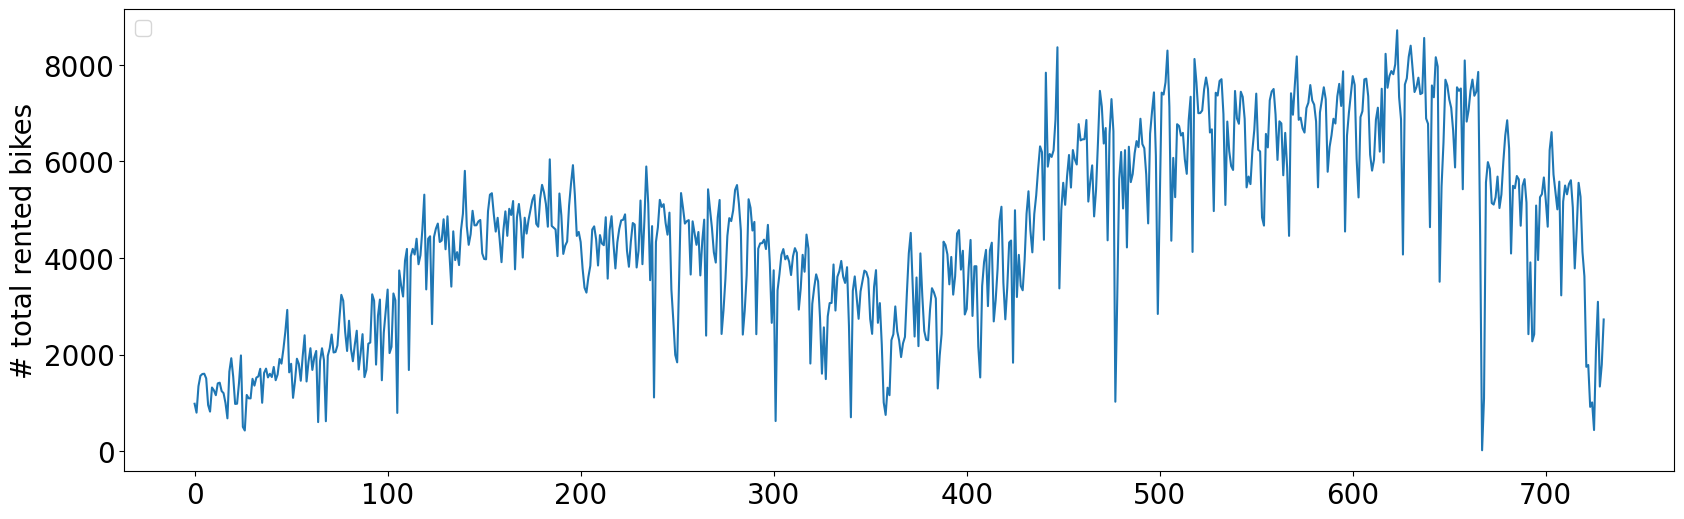

In [ ]:
fig1 = plt.figure(figsize=(20,6))
plt.plot(df_new['cnt'])
#plt.xlabel('Time t',  fontsize=20)
#because we use temperature data, so that the y axis is temperature
plt.ylabel('# total rented bikes',  fontsize=20)
plt.legend(loc='upper left',  fontsize=15)
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
plt.show()

In [ ]:
X_test

array([[ 7.26100000e+03,  7.17500000e+03,  6.82400000e+03, ...,
         7.17500000e+03,  1.26035954e+00, -1.61014201e+00],
       [ 7.17500000e+03,  6.82400000e+03,  5.46400000e+03, ...,
         7.17500000e+03,  1.24918864e+00, -1.60788578e+00],
       [ 6.82400000e+03,  5.46400000e+03,  7.01300000e+03, ...,
         7.01300000e+03, -1.06897210e+00, -7.44093013e-01],
       ...,
       [ 1.74900000e+03,  1.78700000e+03,  9.20000000e+02, ...,
         1.74900000e+03, -7.00875354e-01,  4.08689098e-01],
       [ 1.78700000e+03,  9.20000000e+02,  1.01300000e+03, ...,
         1.34100000e+03, -5.66707479e-01,  6.15554041e-01],
       [ 9.20000000e+02,  1.01300000e+03,  4.41000000e+02, ...,
         1.34100000e+03, -5.75176655e-01,  6.10415999e-01]])

In [ ]:
y_test

array([7286., 5786., 6299., 6544., 6883., 6784., 7347., 7605., 7148.,
       7865., 4549., 6530., 7006., 7375., 7765., 7582., 6053., 5255.,
       6917., 7040., 7697., 7713., 7350., 6140., 5810., 6034., 6864.,
       7112., 6203., 7504., 5976., 8227., 7525., 7767., 7870., 7804.,
       8009., 8714., 7333., 6869., 4073., 7591., 7720., 8167., 8395.,
       7907., 7436., 7538., 7733., 7393., 7415., 8555., 6889., 6778.,
       4639., 7572., 7328., 8156., 7965., 3510., 5478., 6392., 7691.,
       7570., 7282., 7109., 6639., 5875., 7534., 7461., 7509., 5424.,
       8090., 6824., 7058., 7466., 7693., 7359., 7444., 7852., 4459.,
         22., 1096., 5566., 5986., 5847., 5138., 5107., 5259., 5686.,
       5035., 5315., 5992., 6536., 6852., 6269., 4094., 5495., 5445.,
       5698., 5629., 4669., 5499., 5634., 5146., 2425., 3910., 2277.,
       2424., 5087., 3959., 5260., 5323., 5668., 5191., 4649., 6234.,
       6606., 5729., 5375., 5008., 5582., 3228., 5170., 5501., 5319.,
       5532., 5611.,

In [ ]:
#calling the function mlp.
#returning rmse, pearson correlation, and prediction output
rmse_mlp, corr_mlp, y_pred_mlp = mlp(X_train, X_test, y_train, y_test)
#calling the function knn
#returning rmse, pearson correlation, and prediction output
rmse_knn, corr_knn, y_pred_knn = knn(X_train, X_test, y_train, y_test)
rmse_dt, corr_dt, y_pred_dt = dt(X_train, X_test, y_train, y_test)
#rmse_svm, corr_svm, y_pred_svm = svm(X_train, X_test, y_train, y_test)
rmse_rf, corr_rf, y_pred_rf = rf(X_train, X_test, y_train, y_test)

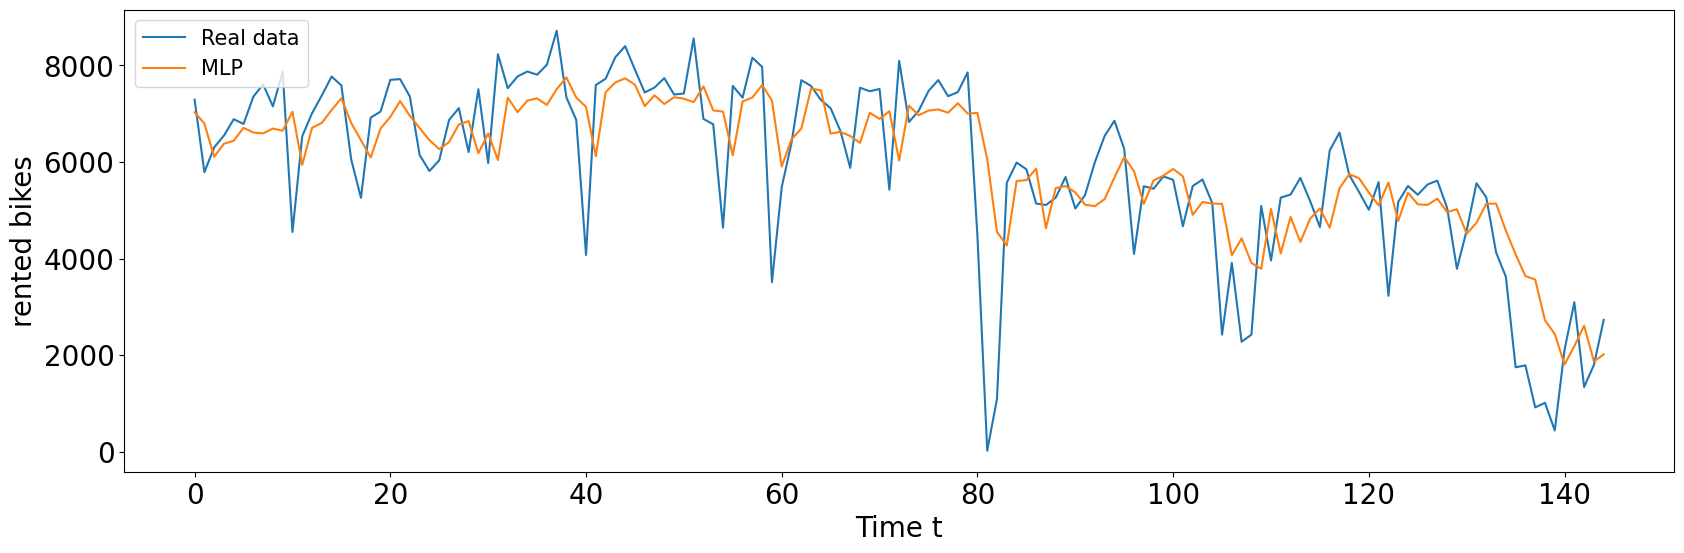

In [ ]:
fig1 = plt.figure(figsize=(20,6))
#plotting the result
# because the total number of test is data is high, so we just print the first 100 data
# y_test[0:100] get the first 100 data from y_test or real test data.
# y_pred_mlp is the prediction result from MLP
# y_pred_knn is the prediction result from KNN
plt.plot(y_test, label='Real data')

#plt.plot(y_pred_knn, label='KNN')
#plt.plot(y_pred_dt, label='DT')
#plt.plot(y_pred_rf, label='RF')

plt.plot(y_pred_mlp, label='MLP')

#title
#pyplot.title('First 100 Test Data')
#the x axis is timestamp, with interval 1 day
plt.xlabel('Time t',  fontsize=20)
#because we use total rented bikes, so that the y axis is rented bikes
plt.ylabel('rented bikes',  fontsize=20)
plt.legend(loc='upper left',  fontsize=15)
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)

plt.show()

In [ ]:
#print out the RMSE , pearson correlation coefficient for MLP and KNN
# low RMSE is better
# high pearson correlation coefficient is better.
print('________________________')
print('MLP')
print('RMSE : %.3f' %rmse_mlp)
print('Pearson correlation coefficient: %.3f' %corr_mlp)

print('________________________')
print('KNN')
print('RMSE : %.3f' %rmse_knn)
print('Pearson correlation coefficient: %.3f' %corr_knn)

print('________________________')
print('DT')
print('RMSE : %.3f' %rmse_dt)
print('Pearson correlation coefficient: %.3f' %corr_dt)

print('________________________')
print('RF')
print('RMSE : %.3f' %rmse_rf)
print('Pearson correlation coefficient: %.3f' %corr_rf)

________________________
MLP
RMSE : 1190.549
Pearson correlation coefficient: 0.778
________________________
KNN
RMSE : 1357.710
Pearson correlation coefficient: 0.696
________________________
DT
RMSE : 1854.465
Pearson correlation coefficient: 0.484
________________________
RF
RMSE : 1324.452
Pearson correlation coefficient: 0.716


In [ ]:
# 1. Impor Pustaka yang Diperlukan
import numpy as np
import pandas as pd
from math import sqrt
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr, kurtosis, skew

# 2. Modifikasi Fungsi split_sequences untuk Multi-Step & Multi-Variate
def split_sequences(sequences, n_steps_in, n_steps_out, target_col_idx=0):
    X, y = list(), list()
    for i in range(len(sequences)):
        # Temukan akhir dari pola input dan output
        end_ix = i + n_steps_in
        out_end_ix = end_ix + n_steps_out

        # Cek apakah sudah melampaui dataset
        if out_end_ix > len(sequences):
            break

        # Kumpulkan bagian input dan output
        seq_x = sequences[i:end_ix, :]
        seq_y = sequences[end_ix:out_end_ix, target_col_idx]
        X.append(seq_x)
        y.append(seq_y)

    return np.array(X), np.array(y)

# 3. Fungsi Feature Engineering
def stats_features(input_data):
    inp = list()
    for i in range(len(input_data)):
        inp2=list()
        inp2=input_data[i]
        min=float(np.min(inp2))
        max=float(np.max(inp2))
        diff=(max-min)
        std=float(np.std(inp2))
        mean=float(np.mean(inp2))
        median=float(np.median(inp2))
        kurt=float(kurtosis(inp2))
        sk=float(skew(inp2))
        inp2=np.append(inp2,min)
        inp2=np.append(inp2,max)
        inp2=np.append(inp2,diff)
        inp2=np.append(inp2,std)
        inp2=np.append(inp2,mean)
        inp2=np.append(inp2,median)
        inp2=np.append(inp2,kurt)
        inp2=np.append(inp2,sk)
        inp=np.append(inp,inp2)
    inp=inp.reshape(len(input_data),-1)
    return inp

# 4. Modifikasi Fungsi Model untuk Evaluasi Multi-Output
# Kita sesuaikan perhitungan korelasi untuk menangani output 2 hari
def evaluate_model(model, X_train, X_test, y_train, y_test):
    # Melatih model
    model.fit(X_train, y_train)

    # Mendapatkan prediksi
    y_pred = model.predict(X_test)
    y_pred = np.round(y_pred, 2) # Pembulatan hingga 2 desimal untuk harga saham

    # Menghitung RMSE (scikit-learn otomatis menghitung rata-rata error untuk multi-output)
    rmse = sqrt(mean_squared_error(y_test, y_pred))

    # Menghitung korelasi Pearson dengan meratakan array (flatten)
    # Ini memberikan korelasi keseluruhan antara semua titik data prediksi dan asli
    corr, _ = pearsonr(y_test.flatten(), y_pred.flatten())

    return rmse, corr, y_pred

In [ ]:
import pandas as pd
from google.colab import drive

drive.mount('/content/drive/')
df = pd.read_csv('/content/drive/MyDrive/Semester 5/Praktikum Penambangan Data/Pertemuan 5/TSLA.csv')
df

# Pra-pemrosesan awal
df['Date'] = pd.to_datetime(df['Date'])
df = df.set_index('Date')

print("5 Baris Pertama Dataset:")
print(df.head())
print("\nInformasi Dataset:")
df.info()

Mounted at /content/drive/
5 Baris Pertama Dataset:
                 Open   High        Low      Close  Adj Close    Volume
Date                                                                   
2010-06-29  19.000000  25.00  17.540001  23.889999  23.889999  18766300
2010-06-30  25.790001  30.42  23.299999  23.830000  23.830000  17187100
2010-07-01  25.000000  25.92  20.270000  21.959999  21.959999   8218800
2010-07-02  23.000000  23.10  18.709999  19.200001  19.200001   5139800
2010-07-06  20.000000  20.00  15.830000  16.110001  16.110001   6866900

Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2416 entries, 2010-06-29 to 2020-02-03
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Open       2416 non-null   float64
 1   High       2416 non-null   float64
 2   Low        2416 non-null   float64
 3   Close      2416 non-null   float64
 4   Adj Close  2416 non-null   float64
 5   Volume     2416

Melatih dan mengevaluasi model MLP...
Melatih dan mengevaluasi model Random Forest...
Melatih dan mengevaluasi model KNN...
Melatih dan mengevaluasi model Decision Tree...

--- Hasil Evaluasi Model (Input: Close) ---
Model: MLP
  RMSE: 14.853
  Pearson Correlation: 0.978
--------------------
Model: Random Forest
  RMSE: 41.130
  Pearson Correlation: 0.834
--------------------
Model: KNN
  RMSE: 41.993
  Pearson Correlation: 0.823
--------------------
Model: Decision Tree
  RMSE: 43.307
  Pearson Correlation: 0.808
--------------------


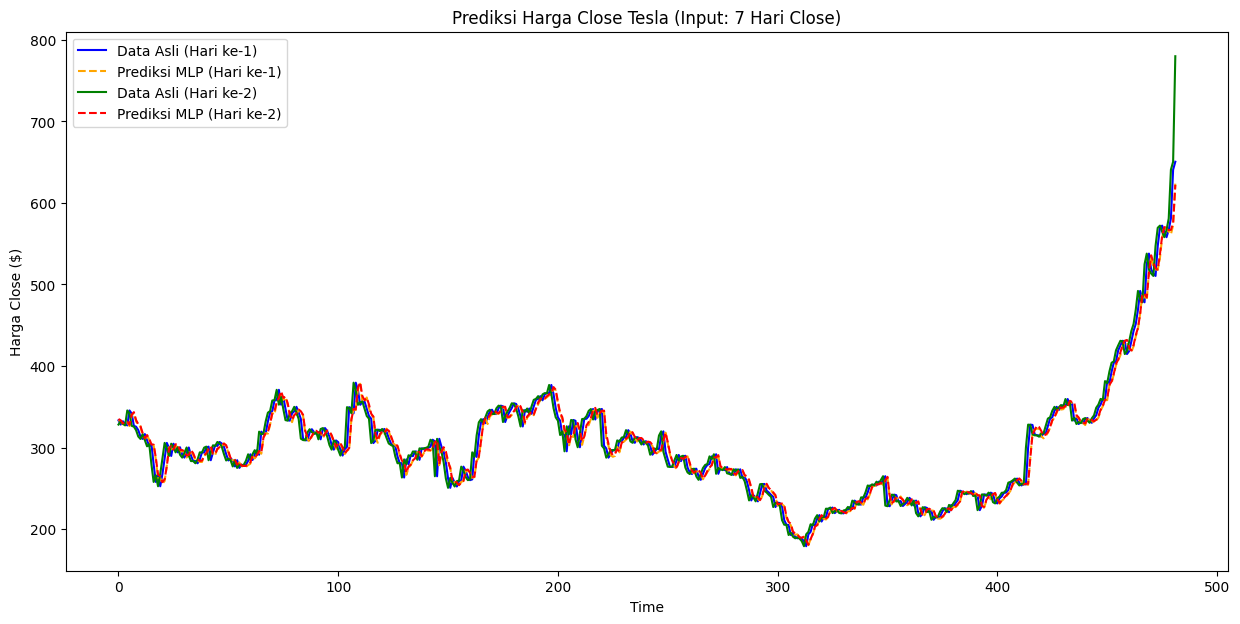

In [ ]:
# Memilih data yang akan digunakan (hanya kolom 'Close')
data_close = df[['Close']].astype(float).values

# Menentukan parameter
n_steps_in, n_steps_out = 7, 2

# Membuat sekuens data dengan fungsi yang sudah dimodifikasi
# Karena hanya ada 1 kolom, target_col_idx = 0
X_close, y_close = split_sequences(data_close, n_steps_in, n_steps_out, target_col_idx=0)

# Mengubah bentuk X dari 3D menjadi 2D agar bisa digunakan model sklearn
# Bentuk awal: (sampel, timesteps, fitur) -> Bentuk baru: (sampel, timesteps * fitur)
n_input = X_close.shape[1] * X_close.shape[2]
X_close = X_close.reshape((X_close.shape[0], n_input))

# Membagi data menjadi set training dan testing
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X_close, y_close, test_size=0.2, shuffle=False)

# Menambahkan fitur statistik
X_train_c = stats_features(X_train_c)
X_test_c = stats_features(X_test_c)

# Inisialisasi model-model
models = {
    "MLP": MLPRegressor(hidden_layer_sizes=(100, 50), max_iter=1000, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "KNN": KNeighborsRegressor(n_neighbors=5),
    "Decision Tree": DecisionTreeRegressor(random_state=42)
}

# Melatih dan mengevaluasi setiap model
results = {}
for name, model in models.items():
    print(f"Melatih dan mengevaluasi model {name}...")
    rmse, corr, y_pred = evaluate_model(model, X_train_c, X_test_c, y_train_c, y_test_c)
    results[name] = {'RMSE': rmse, 'Correlation': corr, 'y_pred': y_pred}

# Menampilkan hasil
print("\n--- Hasil Evaluasi Model (Input: Close) ---")
for name, metrics in results.items():
    print(f"Model: {name}")
    print(f"  RMSE: {metrics['RMSE']:.3f}")
    print(f"  Pearson Correlation: {metrics['Correlation']:.3f}")
    print("-" * 20)

# Visualisasi hasil prediksi model terbaik (misalnya, Random Forest)
best_model_name = min(results, key=lambda k: results[k]['RMSE'])
y_pred_best = results[best_model_name]['y_pred']

plt.figure(figsize=(15, 7))
# Plot prediksi hari pertama (indeks 0) dan hari kedua (indeks 1)
plt.plot(y_test_c[:, 0], label='Data Asli (Hari ke-1)', color='blue')
plt.plot(y_pred_best[:, 0], label=f'Prediksi {best_model_name} (Hari ke-1)', color='orange', linestyle='--')
plt.plot(y_test_c[:, 1], label='Data Asli (Hari ke-2)', color='green')
plt.plot(y_pred_best[:, 1], label=f'Prediksi {best_model_name} (Hari ke-2)', color='red', linestyle='--')
plt.title(f'Prediksi Harga Close Tesla (Input: 7 Hari Close)')
plt.xlabel('Time')
plt.ylabel('Harga Close ($)')
plt.legend()
plt.show()

Melatih dan mengevaluasi model MLP (dengan input Open & Close)...
Melatih dan mengevaluasi model Random Forest (dengan input Open & Close)...
Melatih dan mengevaluasi model KNN (dengan input Open & Close)...
Melatih dan mengevaluasi model Decision Tree (dengan input Open & Close)...

--- Hasil Evaluasi Model (Input: Open & Close) ---
Model: MLP
  RMSE: 15.593
  Pearson Correlation: 0.976
--------------------
Model: Random Forest
  RMSE: 41.557
  Pearson Correlation: 0.830
--------------------
Model: KNN
  RMSE: 41.575
  Pearson Correlation: 0.828
--------------------
Model: Decision Tree
  RMSE: 43.698
  Pearson Correlation: 0.797
--------------------


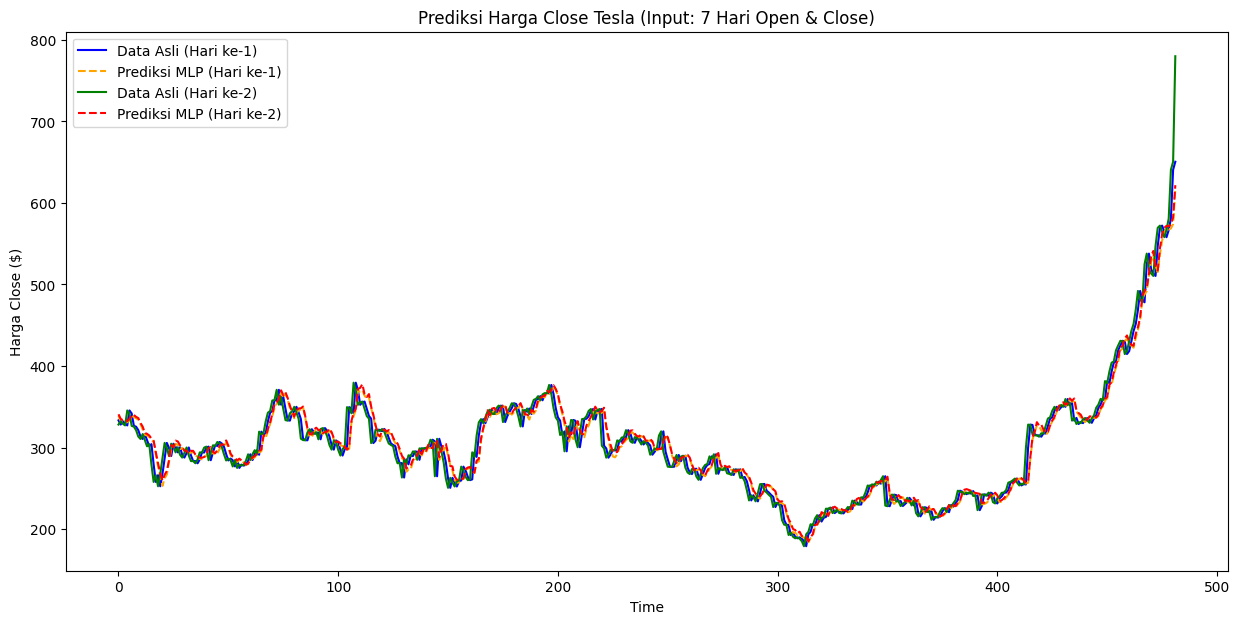

In [ ]:
# Memilih data yang akan digunakan (kolom 'Open' dan 'Close')
# Urutan penting: Open [0], Close [1]
data_open_close = df[['Open', 'Close']].astype(float).values

# Menentukan parameter (sama seperti sebelumnya)
n_steps_in, n_steps_out = 7, 2

# Membuat sekuens data. Targetnya adalah kolom 'Close', yang memiliki indeks 1
X_oc, y_oc = split_sequences(data_open_close, n_steps_in, n_steps_out, target_col_idx=1)

# Mengubah bentuk X dari 3D menjadi 2D
n_input = X_oc.shape[1] * X_oc.shape[2]
X_oc = X_oc.reshape((X_oc.shape[0], n_input))

# Membagi data menjadi set training dan testing
X_train_oc, X_test_oc, y_train_oc, y_test_oc = train_test_split(X_oc, y_oc, test_size=0.2, shuffle=False)

# Menambahkan fitur statistik
X_train_oc = stats_features(X_train_oc)
X_test_oc = stats_features(X_test_oc)

# Inisialisasi ulang model (opsional, tapi praktik yang baik)
models_oc = {
    "MLP": MLPRegressor(hidden_layer_sizes=(100, 50), max_iter=1000, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "KNN": KNeighborsRegressor(n_neighbors=5),
    "Decision Tree": DecisionTreeRegressor(random_state=42)
}

# Melatih dan mengevaluasi setiap model
results_oc = {}
for name, model in models_oc.items():
    print(f"Melatih dan mengevaluasi model {name} (dengan input Open & Close)...")
    rmse, corr, y_pred = evaluate_model(model, X_train_oc, X_test_oc, y_train_oc, y_test_oc)
    results_oc[name] = {'RMSE': rmse, 'Correlation': corr, 'y_pred': y_pred}

# Menampilkan hasil
print("\n--- Hasil Evaluasi Model (Input: Open & Close) ---")
for name, metrics in results_oc.items():
    print(f"Model: {name}")
    print(f"  RMSE: {metrics['RMSE']:.3f}")
    print(f"  Pearson Correlation: {metrics['Correlation']:.3f}")
    print("-" * 20)

# Visualisasi hasil prediksi model terbaik
best_model_name_oc = min(results_oc, key=lambda k: results_oc[k]['RMSE'])
y_pred_best_oc = results_oc[best_model_name_oc]['y_pred']

plt.figure(figsize=(15, 7))
# Plot prediksi hari pertama (indeks 0) dan hari kedua (indeks 1)
plt.plot(y_test_oc[:, 0], label='Data Asli (Hari ke-1)', color='blue')
plt.plot(y_pred_best_oc[:, 0], label=f'Prediksi {best_model_name_oc} (Hari ke-1)', color='orange', linestyle='--')
plt.plot(y_test_oc[:, 1], label='Data Asli (Hari ke-2)', color='green')
plt.plot(y_pred_best_oc[:, 1], label=f'Prediksi {best_model_name_oc} (Hari ke-2)', color='red', linestyle='--')
plt.title(f'Prediksi Harga Close Tesla (Input: 7 Hari Open & Close)')
plt.xlabel('Time')
plt.ylabel('Harga Close ($)')
plt.legend()
plt.show()